# Outliers y ROE con patrimonio negativo

Es la sección 5 de `05_eda_panel.ipynb` como notebook independiente, para trabajar los dos pendientes de `TODO.md` (outliers y ROA/ROE) sin correr todo el EDA. Lee `data/panel.csv`, que sale de `04_build_panel.ipynb`, y **mide y propone: no modifica el panel ni toma decisiones**. Las decisiones se registran después en `docs/decisions.md`.

Las celdas de análisis son copia de las del EDA. Si se cambia algo acá, replicarlo en la sección 5 de `05_eda_panel.ipynb` (o al revés), para que los dos notebooks digan lo mismo.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")

    CANDIDATOS = [
        Path("/content/drive/MyDrive/Colab Notebooks/Diplodatos MAI Grupo 6"),
        Path("/content/drive/MyDrive/Diplodatos MAI Grupo 6"),
    ]
    WORKING_DIR = next((p for p in CANDIDATOS if p.exists()), None)
    if WORKING_DIR is None:
        raise FileNotFoundError(
            "No encuentro la carpeta del grupo. ¿Agregaste el acceso directo "
            "en 'Mi unidad' desde 'Compartido conmigo'?"
        )
else:
    WORKING_DIR = Path.cwd()


In [2]:
panel = pd.read_csv(f"{WORKING_DIR}/data/panel.csv", dtype={"cik": str})
panel

,cik,nombre,sector,trimestre,fecha_presentacion,ingresos_netos,resultado_operativo,resultado_neto,activos_totales,activos_corrientes,...,caja,roe,roa,endeudamiento,liquidez_corriente,fco_ingresos,margen_bruto,margen_operativo,margen_neto,fecha_quiebra
0,1000229,CORE LABORATORIES N V,energia,2018Q1,20200210,170018000.0,32316000.0,23527000.0,597140000.0,220185000.0,...,13244000.0,0.159356,0.039399,NaN,2.110527,0.135827,NaN,0.190074,0.138379,NaN
1,1000229,CORE LABORATORIES N V,energia,2018Q2,20200210,175475000.0,33449000.0,24752000.0,604744000.0,225662000.0,...,13021000.0,0.160954,0.040930,NaN,2.243362,0.153811,NaN,0.190620,0.141057,NaN
2,1000229,CORE LABORATORIES N V,energia,2018Q3,20200210,182146000.0,34879000.0,22412000.0,666597000.0,239125000.0,...,14100000.0,0.142354,0.033622,NaN,2.310186,0.130900,NaN,0.191489,0.123044,NaN
3,1000229,CORE LABORATORIES N V,energia,2018Q4,20210208,173207000.0,17978000.0,8835000.0,648827000.0,230977000.0,...,13116000.0,0.056360,0.013617,NaN,2.252401,0.218819,NaN,0.103795,0.051008,NaN
4,1000229,CORE LABORATORIES N V,energia,2019Q1,20210208,169194000.0,16414000.0,40510000.0,791760000.0,236423000.0,...,13206000.0,0.221167,0.051164,NaN,1.838223,0.148681,NaN,0.097013,0.239429,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5809,96793,SUNLINK HEALTH SYSTEMS INC,salud,2023Q4,20240213,8510000.0,-433000.0,-3075000.0,18787000.0,13710000.0,...,2055000.0,NaN,-0.163677,NaN,2.622418,-0.046181,NaN,-0.050881,-0.361340,NaN
5810,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q1,20240515,7462000.0,-853000.0,-1396000.0,16144000.0,10966000.0,...,1211000.0,NaN,-0.086472,NaN,2.769891,-0.142321,NaN,-0.114313,-0.187081,NaN
5811,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q2,20240930,7913000.0,-675000.0,4288000.0,20612000.0,15664000.0,...,7170000.0,NaN,0.208034,NaN,3.718016,-0.048780,NaN,-0.085303,0.541893,NaN
5812,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q3,20241112,7923000.0,-1194000.0,-549000.0,19629000.0,15616000.0,...,7529000.0,NaN,-0.027969,NaN,4.055051,-0.115487,NaN,-0.150700,-0.069292,NaN


## 0. Preparación

Lo mínimo que necesita la sección: `trimestre` como período trimestral y `fecha_quiebra` como fecha (el CSV las guarda como texto), la lista de los 8 ratios, los dos sectores con su color, `company_sector` (el sector de cada empresa, para contar empresas y no filas) y `summary`, el diccionario donde se guardan los números que van al informe. Después, las tres funciones auxiliares que usan las celdas: `log10_positive` (logaritmo de los valores positivos, el resto queda vacío), `flag_outliers` (marca los valores fuera de umbral; un vacío nunca se marca) y `bankruptcy_within` (si la empresa quiebra dentro de los próximos `horizon` trimestres).


In [3]:
START, END = pd.Period("2018Q1"), pd.Period("2024Q4")

panel["trimestre"] = pd.PeriodIndex(panel["trimestre"], freq="Q")
panel["fecha_quiebra"] = pd.to_datetime(panel["fecha_quiebra"])  # NaT: sin quiebra
panel = panel.sort_values(["cik", "trimestre"]).reset_index(drop=True)
assert not panel.duplicated(["cik", "trimestre"]).any()
assert panel["trimestre"].between(START, END).all()

RATIO_COLUMNS = [
    "roe",
    "roa",
    "endeudamiento",
    "liquidez_corriente",
    "fco_ingresos",
    "margen_bruto",
    "margen_operativo",
    "margen_neto",
]
SECTORS = ["energia", "salud"]
PALETTE = dict(zip(SECTORS, sns.color_palette("colorblind", 2)))
company_sector = panel.groupby("cik")["sector"].first()

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

summary = {}
panel.dtypes


cik                             object
nombre                          object
sector                          object
trimestre                period[Q-DEC]
fecha_presentacion               int64
ingresos_netos                 float64
resultado_operativo            float64
resultado_neto                 float64
activos_totales                float64
activos_corrientes             float64
pasivos_totales                float64
pasivos_corrientes             float64
patrimonio_neto                float64
flujo_caja_operativo           float64
ganancia_bruta                 float64
caja                           float64
roe                            float64
roa                            float64
endeudamiento                  float64
liquidez_corriente             float64
fco_ingresos                   float64
margen_bruto                   float64
margen_operativo               float64
margen_neto                    float64
fecha_quiebra           datetime64[ns]
dtype: object

In [4]:
def log10_positive(s: pd.Series) -> pd.Series:
    """log10 de los valores > 0; el resto (cero, negativos, NaN) queda en NaN."""
    return np.log10(s.where(s > 0))


def flag_outliers(df: pd.DataFrame, thresholds: dict) -> pd.DataFrame:
    """Una columna booleana por ratio: valor < low o valor > high (None = sin límite). Un NaN nunca se marca."""
    flags = {}
    for column, (low, high) in thresholds.items():
        flag = pd.Series(False, index=df.index)
        if low is not None:
            flag |= df[column] < low
        if high is not None:
            flag |= df[column] > high
        flags[column] = flag
    return pd.DataFrame(flags)


def bankruptcy_within(df: pd.DataFrame, horizon: int) -> pd.Series:
    """True si la empresa quiebra dentro de los próximos `horizon` trimestres. Comparar con NaT da False."""
    bq = df["fecha_quiebra"].dt.to_period("Q")
    return (bq > df["trimestre"]) & (bq <= df["trimestre"] + horizon)


## 1. Outliers y ROE con patrimonio negativo

**Qué se mira.** Cuántas filas y empresas quedan marcadas como outliers con umbrales fijos: los de la guía de la mentora (sección 5) para los márgenes, fuera de (−500 %, 200 %), y para el endeudamiento, mayor a 5; y umbrales propuestos con la misma lógica para los demás ratios (valores poco interpretables para una empresa que opera; son una propuesta con criterio propio, no salen de una fuente). Se mide por sector, se caracteriza a las filas marcadas (numerador y denominador de cada ratio) y se compara con la alternativa de recortar a los percentiles 1 y 99 de cada sector (*winsorizar*). Al final, el caso del ROE con patrimonio negativo: cuando el patrimonio es negativo, el signo del ROE se invierte y el ratio engaña (una empresa con ganancia y patrimonio negativo tiene ROE negativo, y una con pérdida y patrimonio negativo tiene ROE positivo).

**Por qué.** Es el pendiente de `TODO.md` y una pregunta del checklist: qué umbral se usa en cada ratio y si se aplica igual en los dos sectores. Un ratio de −100.000 no es información sobre la empresa, y en un modelo lineal o en una media domina a todas las demás filas.

**Conclusión.** Con los umbrales fijos, los ratios más afectados son los márgenes: quedan fuera el 10,4 % de las filas con margen neto en salud y el 6,4 % en energía, y el 9,9 % y 5,3 % del margen operativo. Siguen endeudamiento (6–7 %), ROA (4,5–5,8 %) y FCO/ingresos (2,8 % y 7,2 %); ROE y liquidez corriente, menos del 2 %. Un ratio extremo puede venir de un numerador enorme, de un denominador casi nulo o de los dos, así que se miran ambos. En la fila típica fuera de umbral, el **denominador es cientos o miles de veces menor** que en las filas dentro del umbral (ingresos de 0,1 millones de USD contra 111 en el margen neto; activos de 0,09 contra 307 en el endeudamiento), y el numerador también es menor, no mayor: el extremo viene de dividir por casi nada. Clasificando cada fila fuera de umbral según si su denominador queda por debajo de la mediana de las filas normales y su numerador por encima, en 7 de los 8 ratios entre el 81 % y el 100 % tiene **solo el denominador chico**; el ROE es la excepción (44 % solo denominador, 49 % ambos). Los casos con **solo el numerador grande** son pocos (5 % en los márgenes, 8 % en el ROE), pero son los de empresas grandes con pérdidas enormes. El **80 % de las filas marcadas (557 de 698)** tiene ingresos o activos menores a 1 millón (10^6). La figura de numerador contra denominador muestra lo mismo fila por fila: los puntos fuera de umbral se amontonan a la izquierda de la mediana del denominador, y los pocos de "solo numerador grande" quedan arriba a la derecha, entre las empresas grandes. Buena parte de los extremos viene de denominadores casi nulos, pero no todos: también hay pérdidas muy grandes en empresas grandes (14 filas con margen neto fuera del umbral tienen más de 100 millones de USD de ingresos, por ejemplo Concho Resources en 2020Q1). Estos análisis no permiten descartar errores de carga.

Sectores: en endeudamiento, ROA y ROE los porcentajes son parecidos, pero en los márgenes salud marca casi el doble, porque tiene más empresas con ingresos ínfimos (biotecnológicas sin producto). Los percentiles 1 y 99 difieren mucho entre sectores (P99 del endeudamiento: 817 en energía y 89 en salud; P1 del margen operativo: −47 y −135), así que un recorte por percentiles por sector trata distinto a las mismas situaciones. Además, winsorizar a P1–P99 no alcanza: el desvío del margen neto baja de 2.349 a 12,6, pero la media sigue en −2,4 cuando la mediana es 0,004.

ROE: el patrimonio es negativo en **1.100 filas de 123 empresas**, y en todas ellas el signo del ROE engaña. En 194 filas (87 de energía y 107 de salud) la empresa gana y el ROE es negativo: HCA gana 1.400 millones por trimestre con ROA del 2,4–2,8 % y ROE de −0,6 a −1,0. En 906 filas (627 y 279) la empresa pierde y el ROE es positivo. El gráfico de dispersión muestra los dos cuadrantes del lado izquierdo.

Outliers y quiebra: las filas marcadas no son ruido para el objetivo 3. Entre las filas cuyo año siguiente está dentro del panel (hasta 2023Q4), **el 5,8 % de las que tienen algún ratio fuera de umbral quiebra dentro del año, contra el 2,8 % del resto**; con patrimonio negativo, 6,8 % contra 2,3 %. Los outliers de empresas no minúsculas (132 filas: pérdidas enormes de empresas grandes, como Concho en 2020Q1) quiebran 6 veces más que el resto (16,7 %), y son las primeras que borraría un filtro automático. Las empresas minúsculas, en cambio, quiebran menos (1,5 % contra 3,7 %): no entran en Chapter 11, dejan de presentar (sección 9 de `05_eda_panel.ipynb`). Son 50 quiebras en total, así que los porcentajes de los grupos chicos son poco precisos. Sensibilidad de los 4 umbrales propuestos: solo con los de la guía quedan marcadas 576 filas (9,9 %); con los propuestos a la mitad, 897 (15,4 %); al doble, 625 (10,7 %). Mueven el total en 2–3 puntos y no cambian la conclusión.

**Propuesta** (decisión pendiente del grupo, a registrar en `docs/decisions.md`, sección 13):
1. Usar los umbrales fijos de la guía para los márgenes y el endeudamiento, y los propuestos acá para el resto, **iguales en los dos sectores**: los extremos tienen la misma causa en ambos. **Marcar y no borrar**: una bandera `outlier` por fila, porque las empresas minúsculas y con pérdidas enormes son justamente candidatas a quebrar y borrarlas sesgaría el objetivo 3. Para los modelos sensibles a la escala, recortar los ratios a los umbrales (o a P5–P95) en el momento de entrenar.
2. Agregar una bandera `empresa_minuscula` (ingresos trimestrales o activos menores a 1 millón de USD), que resume la causa.
3. `roe` vacío cuando el patrimonio es ≤ 0, más una bandera `patrimonio_negativo`, y usar el ROA como medida principal de rentabilidad.

filas con algún ratio fuera de umbral: 698 (12.0%), en 142 empresas


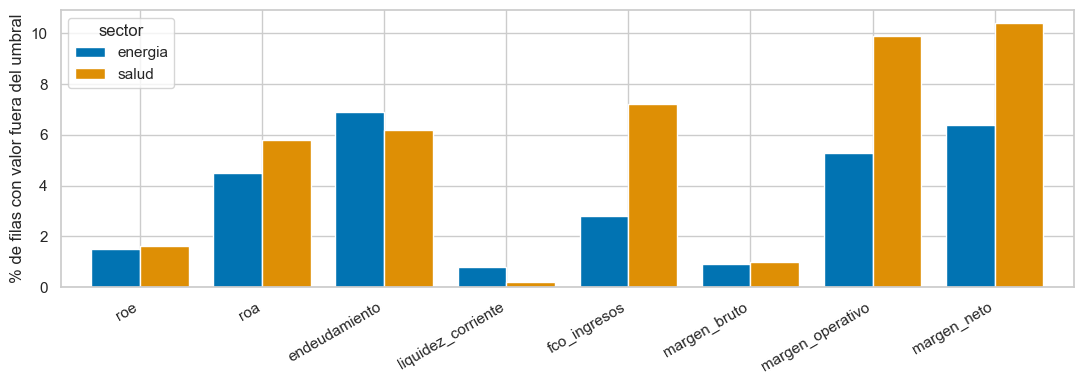

filas       % de filas con valor       empresas      
sector             energia salud              energia salud  energia salud
margen_bruto             3     5                  0.9   1.0        2     4
margen_operativo       146   115                  5.3   9.9       54    16
margen_neto            210   134                  6.4  10.4       74    18
endeudamiento          210    84                  6.9   6.2       25    11
roa                    180    96                  4.5   5.8       38    17
roe                     52    26                  1.5   1.6       36    19
liquidez_corriente      33     4                  0.8   0.2        8     2
fco_ingresos            93    94                  2.8   7.2       23    13

In [5]:
THRESHOLDS = {
    # guía de la mentora, sección 5: márgenes fuera de (-500 %, 200 %) y endeudamiento > 5
    "margen_bruto": (-5, 2),
    "margen_operativo": (-5, 2),
    "margen_neto": (-5, 2),
    "endeudamiento": (None, 5),
    # propuesta nuestra para los demás ratios (sin fuente): valores poco interpretables para una empresa que opera
    "roa": (-1, 1),
    "roe": (-5, 5),
    "liquidez_corriente": (None, 50),
    "fco_ingresos": (-5, 5),
}
flags = flag_outliers(panel, THRESHOLDS)
with_value = panel[list(THRESHOLDS)].notna()
out_rows = flags.groupby(panel["sector"]).sum().T
out_pct = (
    flags.groupby(panel["sector"]).sum() / with_value.groupby(panel["sector"]).sum() * 100
).round(1).T
out_companies = flags.groupby(panel["cik"]).any().groupby(company_sector).sum().T
outliers = pd.concat(
    {"filas": out_rows, "% de filas con valor": out_pct, "empresas": out_companies}, axis=1
)
any_flag = flags.any(axis=1)
summary["filas_con_algun_outlier"] = int(any_flag.sum())
summary["empresas_con_algun_outlier"] = panel.loc[any_flag, "cik"].nunique()
for ratio in ["margen_neto", "endeudamiento", "roe"]:
    for sector in SECTORS:
        summary[f"pct_outliers_{ratio}_{sector}"] = out_pct.loc[ratio, sector]
print(f"filas con algún ratio fuera de umbral: {any_flag.sum()} ({any_flag.mean() * 100:.1f}%), "
      f"en {panel.loc[any_flag, 'cik'].nunique()} empresas")

ax = out_pct.loc[RATIO_COLUMNS, SECTORS].plot.bar(color=[PALETTE[s] for s in SECTORS], width=0.8)
ax.set_ylabel("% de filas con valor fuera del umbral")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
outliers

,filas fuera,|numerador| fuera (M USD),|numerador| dentro (M USD),|denominador| fuera (M USD),|denominador| dentro (M USD)
ratio,,,,,
roe,78,23.10,9.53,0.98,168.87
roa,276,0.73,10.72,0.07,597.16
endeudamiento,294,3.80,107.20,0.09,306.60
liquidez_corriente,37,8.75,84.90,0.12,69.70
fco_ingresos,187,0.55,17.76,0.03,99.72
margen_bruto,8,0.08,10.94,0.01,52.13
margen_operativo,261,1.48,13.87,0.08,92.96
margen_neto,344,2.14,15.14,0.10,111.43


,solo denominador chico (%),ambos (%),solo numerador grande (%)
ratio,,,
roe,43.6,48.7,7.7
roa,88.4,10.1,1.4
endeudamiento,99.3,0.7,0.0
liquidez_corriente,100.0,0.0,0.0
fco_ingresos,96.3,3.7,0.0
margen_bruto,100.0,0.0,0.0
margen_operativo,83.1,11.9,5.0
margen_neto,80.8,14.2,4.9


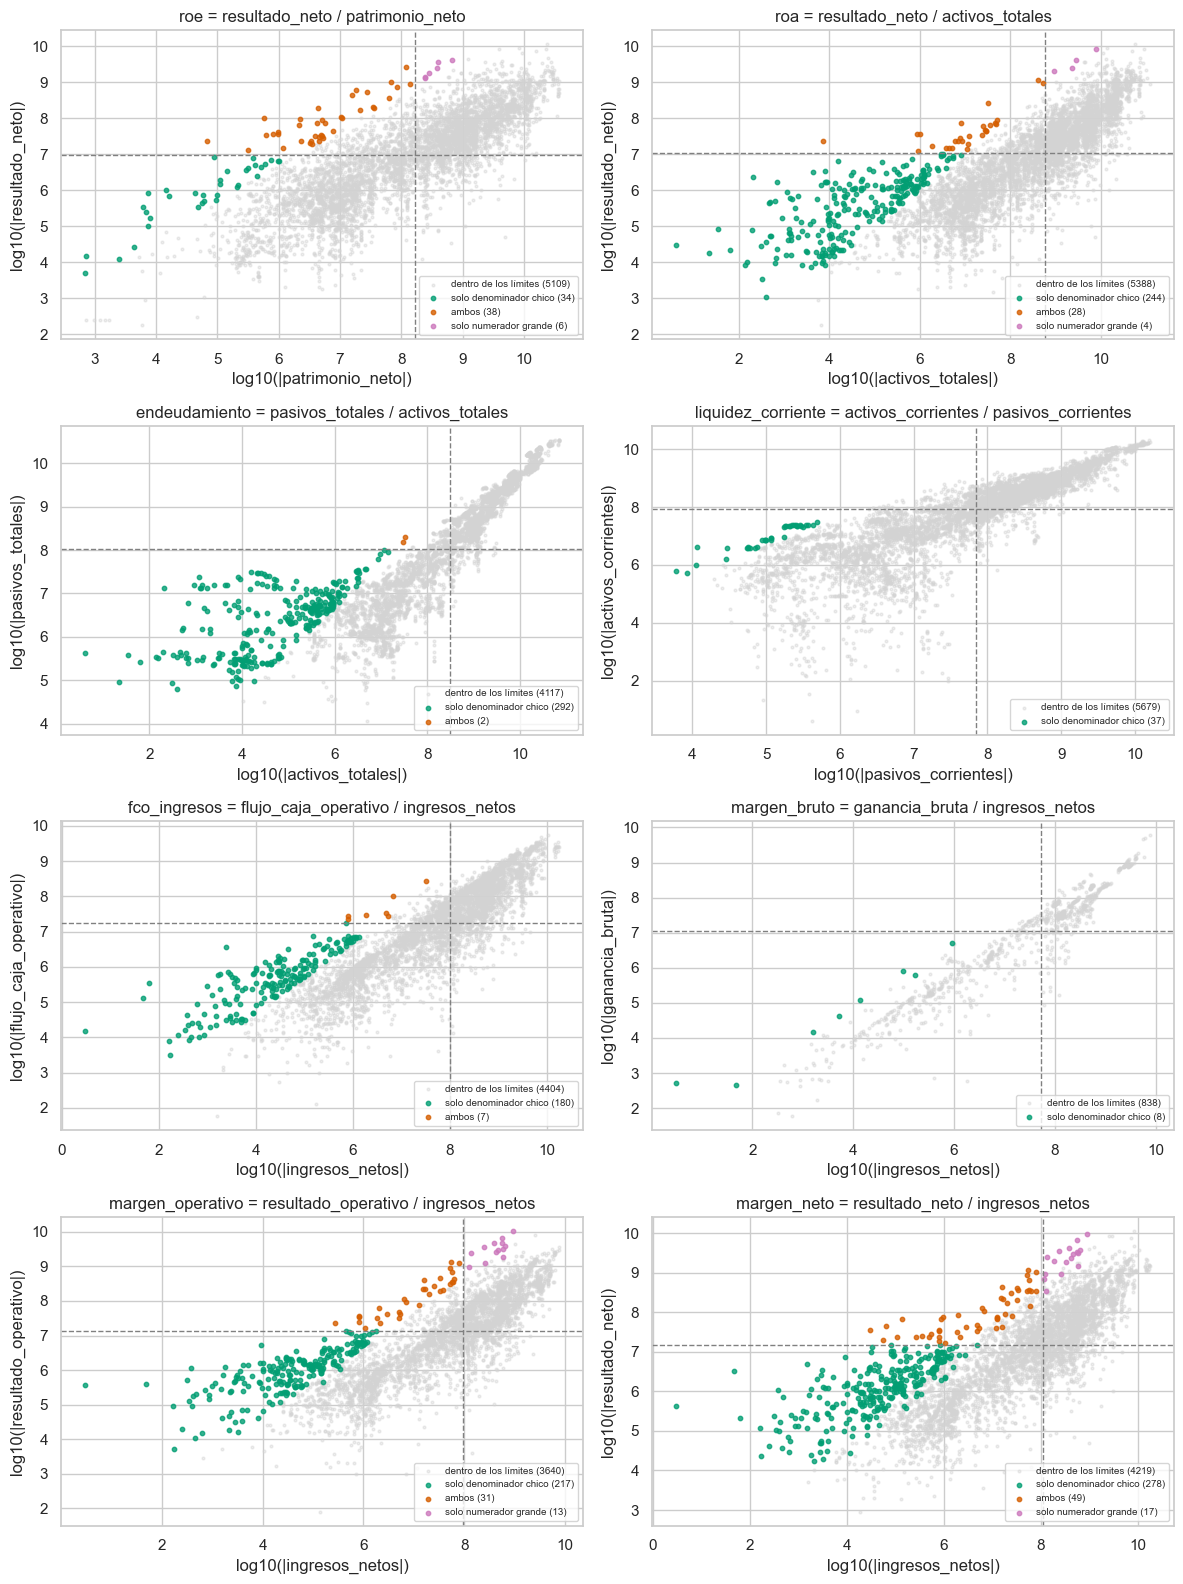

In [6]:
# ¿De dónde vienen los outliers? Un ratio extremo puede venir de un numerador muy grande,
# de un denominador muy chico o de ambos. Por eso, para cada ratio se separan las filas
# fuera y dentro de sus límites, y se arman dos tablas:
# 1. Tamaños típicos: mediana del numerador y del denominador, en valor absoluto, en cada grupo.
# 2. Clasificación de las filas fuera de límite: el numerador es "grande" si supera la mediana
#    de las filas dentro de los límites, y el denominador es "chico" si queda por debajo de la suya.
# Las tablas describen los valores, pero no demuestran qué causó cada valor extremo.
RATIO_PARTS = {
    "roe": ("resultado_neto", "patrimonio_neto"),
    "roa": ("resultado_neto", "activos_totales"),
    "endeudamiento": ("pasivos_totales", "activos_totales"),
    "liquidez_corriente": ("activos_corrientes", "pasivos_corrientes"),
    "fco_ingresos": ("flujo_caja_operativo", "ingresos_netos"),
    "margen_bruto": ("ganancia_bruta", "ingresos_netos"),
    "margen_operativo": ("resultado_operativo", "ingresos_netos"),
    "margen_neto": ("resultado_neto", "ingresos_netos"),
}
rows = []
for ratio, (numerator, denominator) in RATIO_PARTS.items():
    outside = flags[ratio]
    inside = panel[ratio].notna() & ~outside
    num, den = panel[numerator].abs(), panel[denominator].abs()  # importa el tamaño, no el signo
    num_typical, den_typical = num[inside].median(), den[inside].median()
    big_num, small_den = num > num_typical, den < den_typical
    rows.append({
        "ratio": ratio,
        "filas fuera": int(outside.sum()),
        "|numerador| fuera (M USD)": num[outside].median() / 1e6,
        "|numerador| dentro (M USD)": num_typical / 1e6,
        "|denominador| fuera (M USD)": den[outside].median() / 1e6,
        "|denominador| dentro (M USD)": den_typical / 1e6,
        "solo denominador chico (%)": (outside & small_den & ~big_num).sum() / outside.sum() * 100,
        "ambos (%)": (outside & small_den & big_num).sum() / outside.sum() * 100,
        "solo numerador grande (%)": (outside & ~small_den & big_num).sum() / outside.sum() * 100,
    })
ratio_parts = pd.DataFrame(rows).set_index("ratio")
# tabla 1: tamaño típico del numerador y del denominador (medianas de los valores absolutos)
display(ratio_parts.iloc[:, :5].round(2))
# tabla 2: filas fuera de límite con solo el denominador chico, con ambos o con solo el numerador grande
display(ratio_parts.iloc[:, 5:].round(1))
summary["pct_margen_neto_fuera_solo_denominador"] = round(
    ratio_parts.loc["margen_neto", "solo denominador chico (%)"], 1
)

# Figura: numerador contra denominador de cada ratio, los dos en log10 del valor absoluto
# (cada unidad del eje multiplica por 10; 6 = 1 millón de USD). Es la tabla 2 fila por fila:
# las filas dentro de los límites van en gris y las de fuera, con el color de su categoría.
# Las líneas punteadas son las medianas de las filas dentro de los límites: a la izquierda de la
# vertical el denominador es "chico", por encima de la horizontal el numerador es "grande".
# Las filas con numerador o denominador igual a 0 no se dibujan (no tienen logaritmo).
CATEGORIES = ["solo denominador chico", "ambos", "solo numerador grande"]
CATEGORY_COLORS = dict(zip(CATEGORIES, sns.color_palette("colorblind", 5)[2:]))
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
for ax, (ratio, (numerator, denominator)) in zip(axes.flat, RATIO_PARTS.items()):
    outside = flags[ratio]
    num, den = panel[numerator].abs(), panel[denominator].abs()
    num_typical = ratio_parts.loc[ratio, "|numerador| dentro (M USD)"] * 1e6
    den_typical = ratio_parts.loc[ratio, "|denominador| dentro (M USD)"] * 1e6
    big_num, small_den = num > num_typical, den < den_typical
    category = pd.Series("dentro de los límites", index=panel.index)
    category[outside & small_den & ~big_num] = CATEGORIES[0]
    category[outside & small_den & big_num] = CATEGORIES[1]
    category[outside & ~small_den & big_num] = CATEGORIES[2]
    data = pd.DataFrame(
        {"x": log10_positive(den), "y": log10_positive(num), "categoria": category}
    ).dropna()
    inside = data[data["categoria"] == "dentro de los límites"]
    ax.scatter(inside["x"], inside["y"], s=4, color="lightgray", alpha=0.4,
               label=f"dentro de los límites ({len(inside)})")
    for name, color in CATEGORY_COLORS.items():
        part = data[data["categoria"] == name]
        if len(part):
            ax.scatter(part["x"], part["y"], s=10, color=color, alpha=0.8, label=f"{name} ({len(part)})")
    ax.axvline(np.log10(den_typical), color="gray", linestyle="--", linewidth=1)
    ax.axhline(np.log10(num_typical), color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{ratio} = {numerator} / {denominator}")
    ax.set_xlabel(f"log10(|{denominator}|)")
    ax.set_ylabel(f"log10(|{numerator}|)")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()


In [7]:
# alternativa: winsorizar a P1 y P99 de cada sector
def winsorize_by_sector(df: pd.DataFrame, columns: list, lower=0.01, upper=0.99) -> pd.DataFrame:
    """Recorta cada columna a sus percentiles dentro de cada sector."""
    return df.groupby("sector")[columns].transform(
        lambda s: s.clip(s.quantile(lower), s.quantile(upper))
    )


winsorized = winsorize_by_sector(panel, RATIO_COLUMNS)
moments = pd.concat(
    {
        "original": panel[RATIO_COLUMNS].agg(["mean", "std"]).T,
        "winsorizado P1-P99 por sector": winsorized.agg(["mean", "std"]).T,
        "mediana": panel[RATIO_COLUMNS].median().rename("P50").to_frame(),
    },
    axis=1,
)
display(moments.round(3))

# ¿P1 y P99 difieren entre sectores? (si es así, un único umbral los trata distinto)
panel.groupby("sector")[RATIO_COLUMNS].quantile([0.01, 0.99]).round(2)

original           winsorizado P1-P99 por sector          \
                       mean       std                          mean     std   
roe                   0.124     6.354                        -0.004   0.673   
roa                  -2.658   196.376                        -0.512   3.392   
endeudamiento        78.751  1936.099                        10.262  77.737   
liquidez_corriente    3.214     9.246                         2.880   5.503   
fco_ingresos         -4.129   118.420                        -0.612   5.446   
margen_bruto          0.018     6.208                         0.217   0.736   
margen_operativo    -39.024  2028.404                        -1.995  10.761   
margen_neto         -52.838  2348.610                        -2.392  12.616   

                   mediana  
                       P50  
roe                  0.016  
roa                 -0.002  
endeudamiento        0.491  
liquidez_corriente   1.249  
fco_ingresos         0.173  
margen_bruto         0.301  
margen_operativo     0.032  
margen_neto          0.004

roe    roa  endeudamiento  liquidez_corriente  fco_ingresos  \
sector                                                                       
energia 0.01 -3.36 -33.28           0.02                0.00        -20.34   
        0.99  2.97   0.24         817.48               40.08          2.13   
salud   0.01 -4.82 -11.17           0.04                0.01        -71.57   
        0.99  3.48   0.29          88.67               29.59          1.97   

              margen_bruto  margen_operativo  margen_neto  
sector                                                     
energia 0.01         -4.80            -46.64       -76.03  
        0.99          1.00              1.04         2.82  
salud   0.01         -3.25           -134.77      -134.99  
        0.99          1.20              0.70         1.81

patrimonio_neto         cero  negativo  positivo
sector  resultado_neto                          
energia negativo           3       627      1374
        positivo           0        87      1475
salud   negativo           0       279       569
        positivo           0       107       669

filas con ROE de signo engañoso (patrimonio < 0): 1100, en 123 empresas


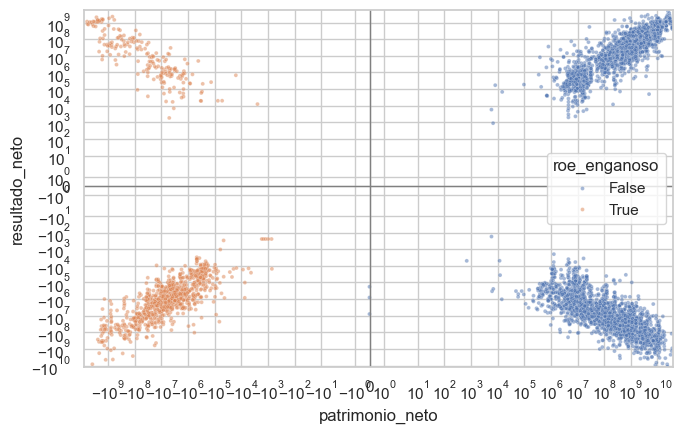

,trimestre,resultado_neto,patrimonio_neto,roe,roa
5213,2024Q1,1.591000e+09,-1.615000e+09,-0.985139,0.027931
5214,2024Q2,1.461000e+09,-1.600000e+09,-0.913125,0.025462
5215,2024Q3,1.270000e+09,-2.182000e+09,-0.582035,0.021359
5216,2024Q4,1.438000e+09,-2.499000e+09,-0.575430,0.024163


In [8]:
# ROE con patrimonio negativo: el signo del ratio se invierte
both = panel[["resultado_neto", "patrimonio_neto"]].notna().all(axis=1)
sign = np.sign(panel.loc[both, ["resultado_neto", "patrimonio_neto"]]).replace(
    {-1: "negativo", 0: "cero", 1: "positivo"}
)
display(pd.crosstab(
    [panel.loc[both, "sector"], sign["resultado_neto"]], sign["patrimonio_neto"],
    rownames=["sector", "resultado_neto"], colnames=["patrimonio_neto"],
))

misleading = both & (panel["patrimonio_neto"] < 0) & (panel["resultado_neto"] != 0)
summary["filas_roe_signo_enganoso"] = int(misleading.sum())
summary["empresas_roe_signo_enganoso"] = panel.loc[misleading, "cik"].nunique()
print(f"filas con ROE de signo engañoso (patrimonio < 0): {misleading.sum()}, "
      f"en {panel.loc[misleading, 'cik'].nunique()} empresas")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(
    data=panel.assign(roe_enganoso=misleading), x="patrimonio_neto", y="resultado_neto",
    hue="roe_enganoso", s=8, alpha=0.5, ax=ax,
)
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.axvline(0, color="gray", linewidth=1)
ax.axhline(0, color="gray", linewidth=1)
plt.tight_layout()
plt.show()

# HCA: ganancia en cada trimestre, patrimonio negativo, ROE negativo
panel.loc[panel["cik"] == "860730", ["trimestre", "resultado_neto", "patrimonio_neto", "roe", "roa"]].tail(4)

In [9]:
# ¿Las filas marcadas informan sobre la quiebra? Tasa de quiebra dentro de 1 año, por grupo
HORIZON = 4  # trimestres
observable = panel["trimestre"] + HORIZON <= END  # filas cuyo año siguiente está dentro del panel
bankrupt_1y = bankruptcy_within(panel, HORIZON)
tiny_company = (panel["ingresos_netos"] < 1e6) | (panel["activos_totales"] < 1e6)
negative_equity = panel["patrimonio_neto"] < 0
GROUPS = {
    "algún ratio fuera de umbral": any_flag,
    "outlier en empresa minúscula": any_flag & tiny_company,
    "outlier en empresa no minúscula": any_flag & ~tiny_company,
    "empresa minúscula (ingresos o activos < 1 M USD)": tiny_company,
    "patrimonio negativo": negative_equity,
    "patrimonio negativo con pérdida": negative_equity & (panel["resultado_neto"] < 0),
    "patrimonio negativo con ganancia": negative_equity & (panel["resultado_neto"] > 0),
}
rows = []
for name, mask in GROUPS.items():
    inside, outside = mask & observable, ~mask & observable
    rows.append({
        "grupo": name,
        "filas": int(inside.sum()),
        "quiebra a 1 año (%)": bankrupt_1y[inside].mean() * 100,
        "resto del panel (%)": bankrupt_1y[outside].mean() * 100,
    })
bankruptcy_by_group = pd.DataFrame(rows).set_index("grupo")
bankruptcy_by_group["veces"] = (
    bankruptcy_by_group["quiebra a 1 año (%)"] / bankruptcy_by_group["resto del panel (%)"]
)
print(f"filas con el año siguiente observable (hasta {END - HORIZON}): {observable.sum()}, "
      f"empresas que quiebran dentro de ese año: {panel.loc[observable & bankrupt_1y, 'cik'].nunique()}")
display(bankruptcy_by_group.round(1))
summary["pct_quiebra_1a_outlier"] = round(bankruptcy_by_group.loc["algún ratio fuera de umbral", "quiebra a 1 año (%)"], 1)
summary["pct_quiebra_1a_sin_outlier"] = round(bankruptcy_by_group.loc["algún ratio fuera de umbral", "resto del panel (%)"], 1)
summary["pct_quiebra_1a_patrimonio_negativo"] = round(bankruptcy_by_group.loc["patrimonio negativo", "quiebra a 1 año (%)"], 1)

# sensibilidad: filas marcadas si los 4 umbrales propuestos se reducen a la mitad o se duplican
PROPOSED = ["roa", "roe", "liquidez_corriente", "fco_ingresos"]
sensitivity = {}
for label, factor in [("solo guía (sin los 4 propuestos)", None), ("propuestos × 0,5", 0.5),
                      ("propuestos × 1", 1), ("propuestos × 2", 2)]:
    thresholds = {r: b for r, b in THRESHOLDS.items() if r not in PROPOSED}
    if factor is not None:
        thresholds.update({
            r: tuple(None if b is None else b * factor for b in THRESHOLDS[r]) for r in PROPOSED
        })
    flagged = flag_outliers(panel, thresholds).any(axis=1)
    sensitivity[label] = {
        "filas": int(flagged.sum()), "% de filas": flagged.mean() * 100,
        "empresas": panel.loc[flagged, "cik"].nunique(),
    }
pd.DataFrame(sensitivity).T.round(1)


filas con el año siguiente observable (hasta 2023Q4): 5256, empresas que quiebran dentro de ese año: 50


,filas,quiebra a 1 año (%),resto del panel (%),veces
grupo,,,,
algún ratio fuera de umbral,657,5.8,2.8,2.0
outlier en empresa minúscula,525,3.0,3.2,0.9
outlier en empresa no minúscula,132,16.7,2.9,5.8
empresa minúscula (ingresos o activos < 1 M USD),1072,1.5,3.7,0.4
patrimonio negativo,1022,6.8,2.3,2.9
patrimonio negativo con pérdida,838,7.4,2.4,3.1
patrimonio negativo con ganancia,183,4.4,3.2,1.4


,filas,% de filas,empresas
solo guía (sin los 4 propuestos),576.0,9.9,108.0
"propuestos × 0,5",897.0,15.4,172.0
propuestos × 1,698.0,12.0,142.0
propuestos × 2,625.0,10.7,120.0


In [10]:
pd.Series(summary)


filas_con_algun_outlier                    698.0
empresas_con_algun_outlier                 142.0
pct_outliers_margen_neto_energia             6.4
pct_outliers_margen_neto_salud              10.4
pct_outliers_endeudamiento_energia           6.9
pct_outliers_endeudamiento_salud             6.2
pct_outliers_roe_energia                     1.5
pct_outliers_roe_salud                       1.6
pct_margen_neto_fuera_solo_denominador      80.8
filas_roe_signo_enganoso                  1100.0
empresas_roe_signo_enganoso                123.0
pct_quiebra_1a_outlier                       5.8
pct_quiebra_1a_sin_outlier                   2.8
pct_quiebra_1a_patrimonio_negativo           6.8
dtype: float64